<div style="width: 100%; clear: both;">
<div style="float: left; width: 30%;">
<img src="https://upload.wikimedia.org/wikipedia/commons/f/f7/Universidad_T%C3%A9cnica_Patricular_de_Loja.png" align="left" width="260">
</div>
<div style="float: right; width: 70%;">
<p style="margin: 0; padding-top: 22px; text-align:right; color:#003366; font-size:16px"><u>Análisis de Datos y Visualización (CICO2000)</u></p>
<p style="margin: 0; text-align:right; color:#999999; font-size:15px">Ingeniería en Redes y Analítica de Datos</p>
</div>
</div>
<div style="width:100%; clear: both;">&nbsp;</div>

# Notebook 2.2 · Consumo de datos mediante APIs y escritura persistente

## Introducción
En el Notebook 2.1 los datos estaban en un archivo local. Ahora los obtendremos de **servicios externos** mediante **APIs REST**, que responden a solicitudes HTTP con datos, normalmente en formato **JSON**. Al final, guardaremos los resultados de forma **persistente** junto con sus **metadatos**.

**Objetivos**
1. Revisar la documentación de una API e identificar su endpoint, parámetros, autenticación y límites de uso.
2. Enviar solicitudes `GET` con la librería `requests` e interpretar el código de estado, los encabezados y el cuerpo de la respuesta.
3. Convertir respuestas JSON (incluso anidadas) en DataFrames.
4. Usar una **API key** de forma responsable.
5. Guardar los datos obtenidos en CSV, JSON y Parquet, con un archivo de metadatos.

**Estructura del notebook**

| Parte | Proveedor | Autenticación | Datos |
|---|---|---|---|
| 1 | Banco Mundial · *Indicators API* | No requiere | Indicadores de conectividad (uso de Internet, banda ancha, telefonía móvil) |
| 2 | ipgeolocation.io · *IP Geolocation API* | **API key** | Ubicación, ASN (sistema autónomo) y zona horaria de direcciones IP |
| 3 | — | — | Escritura persistente de los resultados y sus metadatos |
| 4 | — | — | Ejercicios |

**El flujo que seguiremos en ambas APIs**

`Documentación → endpoint y parámetros → solicitud GET → validar la respuesta → JSON → DataFrame → guardar`

> ⚠️ **Ponga atención:** este notebook necesita **conexión a Internet**. Ejecútelo en Google Colab o en Jupyter con acceso a la red. Las respuestas cambian con el tiempo (los proveedores actualizan sus datos), así que sus resultados pueden diferir de los mostrados aquí.

## 0. Preparación

In [1]:
import json                                   # leer y escribir JSON con Python estándar
import os                                     # crear carpetas, leer variables de entorno
import time                                   # pausas entre solicitudes
from datetime import datetime, timezone       # fecha y hora de extracción (metadatos)

import requests                               # solicitudes HTTP
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("datos", exist_ok=True)           # carpeta donde guardaremos los resultados
print("requests:", requests.__version__, "| pandas:", pd.__version__)

requests: 2.32.3 | pandas: 2.3.3


---
# PARTE 1 · API sin autenticación: Banco Mundial
## 1.1 Revisar la documentación
**Documentación:** https://datahelpdesk.worldbank.org/knowledgebase/articles/889392-about-the-indicators-api-documentation

La *Indicators API* del Banco Mundial da acceso a más de 45 bases de datos (entre ellas, los *World Development Indicators*) con miles de indicadores por país y por año. Es pública: **no requiere registro ni API key**. Los datos se publican con licencia **CC BY 4.0**.

Antes de programar, extraemos de la documentación la información que pide la guía didáctica:

| Elemento | Valor en esta API |
|---|---|
| URL base | `https://api.worldbank.org/v2/` |
| Endpoint de países | `country/{código}` (p. ej. `country/ec`) |
| Endpoint de indicadores | `country/{códigos}/indicator/{id_indicador}` |
| Método | `GET` |
| Parámetros útiles | `format=json`, `date=2010:2023` (rango de años), `per_page` (registros por página), `page` |
| Autenticación | Ninguna |
| Formato de respuesta | JSON (o XML por defecto) |
| Paginación | Sí: 50 registros por página por defecto |

**Indicadores relacionados con redes y telecomunicaciones**

| Código | Indicador |
|---|---|
| `IT.NET.USER.ZS` | Personas que usan Internet (% de la población) |
| `IT.NET.BBND.P2` | Suscripciones de banda ancha fija (por cada 100 personas) |
| `IT.CEL.SETS.P2` | Suscripciones a telefonía celular móvil (por cada 100 personas) |
| `IT.NET.SECR.P6` | Servidores de Internet seguros (por millón de personas) |

## 1.2 Primera solicitud y anatomía de la respuesta
`requests.get()` envía la solicitud y devuelve un objeto `Response`. Los parámetros se pasan en un **diccionario** `params`: `requests` los añade a la URL por usted (`?format=json&...`).

Toda respuesta tiene tres partes: **código de estado**, **encabezados** y **cuerpo**.

In [2]:
URL_BASE_BM = "https://api.worldbank.org/v2/"

respuesta = requests.get(
    URL_BASE_BM + "country/ec",       # endpoint: recurso 'país' con código 'ec' (Ecuador)
    params={"format": "json"},        # pedimos la respuesta en JSON
    timeout=30                        # si el servidor no responde en 30 s, se detiene la espera
)

print("URL enviada:   ", respuesta.url)                          # URL completa con parámetros
print("Código estado: ", respuesta.status_code)                  # 200 = éxito
print("Content-Type:  ", respuesta.headers.get("Content-Type"))  # encabezado: formato del cuerpo
print("Cuerpo (texto):", respuesta.text[:250], "...")            # primeros caracteres del cuerpo

URL enviada:    https://api.worldbank.org/v2/country/ec?format=json
Código estado:  200
Content-Type:   application/json;charset=utf-8
Cuerpo (texto): [{"page":1,"pages":1,"per_page":"50","total":1},[{"id":"ECU","iso2Code":"EC","name":"Ecuador","region":{"id":"LCN","iso2code":"ZJ","value":"Latin America & Caribbean "},"adminregion":{"id":"LAC","iso2code":"XJ","value":"Latin America & Caribbean (exc ...


> ⚠️ **Ponga atención**
> - Use siempre `timeout`: sin él, si el servidor no responde, la celda puede quedarse esperando indefinidamente.
> - `respuesta.text` es el cuerpo como **texto**; `respuesta.json()` lo convierte en **estructuras de Python** (listas y diccionarios).

## 1.3 Interpretar el JSON
La respuesta del Banco Mundial es una **lista de dos elementos**:
- posición `0`: metadatos de la consulta (página, número de páginas, total de registros);
- posición `1`: una lista con los registros solicitados.

In [3]:
datos = respuesta.json()

print(type(datos), "con", len(datos), "elementos")
print("Metadatos:", datos[0])

pais = datos[1][0]                                  # primer (y único) registro de la lista de datos
print("\nClaves del registro:", list(pais.keys()))

<class 'list'> con 2 elementos
Metadatos: {'page': 1, 'pages': 1, 'per_page': '50', 'total': 1}

Claves del registro: ['id', 'iso2Code', 'name', 'region', 'adminregion', 'incomeLevel', 'lendingType', 'capitalCity', 'longitude', 'latitude']


In [4]:
# Navegación por claves: algunos valores son a su vez diccionarios (JSON anidado)
print("Id:      ", pais["id"])
print("Nombre:  ", pais["name"])
print("Capital: ", pais["capitalCity"])
print("Región:  ", pais["region"]["value"])          # diccionario dentro de diccionario
print("Ingreso: ", pais["incomeLevel"]["value"])

Id:       ECU
Nombre:   Ecuador
Capital:  Quito
Región:   Latin America & Caribbean 
Ingreso:  Upper middle income


### Una función reutilizable
Esta es una versión mejorada de la función del notebook original: valida el código de estado, detecta los mensajes de error de la API y **devuelve** (`return`) un diccionario en lugar de solo imprimir.

In [5]:
def info_pais(codigo):
    """Consulta la API del Banco Mundial y devuelve un diccionario con datos básicos del país."""
    r = requests.get(URL_BASE_BM + f"country/{codigo}", params={"format": "json"}, timeout=30)
    if r.status_code != 200:
        print(f"Error HTTP {r.status_code} al consultar '{codigo}'")
        return None

    contenido = r.json()
    # Si el código no existe, la API responde 200 pero con un 'message' en lugar de datos
    if len(contenido) < 2 or contenido[1] is None:
        print(f"La API no devolvió datos para '{codigo}':", contenido[0].get("message"))
        return None

    p = contenido[1][0]
    return {"iso3": p["id"], "pais": p["name"], "capital": p["capitalCity"],
            "region": p["region"]["value"], "ingreso": p["incomeLevel"]["value"],
            "lat": float(p["latitude"]), "lon": float(p["longitude"])}


print(info_pais("ec"))
print(info_pais("xx"))          # código inexistente

{'iso3': 'ECU', 'pais': 'Ecuador', 'capital': 'Quito', 'region': 'Latin America & Caribbean ', 'ingreso': 'Upper middle income', 'lat': -0.229498, 'lon': -78.5243}
La API no devolvió datos para 'xx': [{'id': '120', 'key': 'Invalid value', 'value': 'The provided parameter value is not valid'}]
None


> ⚠️ **Ponga atención:** un código **200 no garantiza que haya datos**. Algunas APIs, como la del Banco Mundial, responden 200 e incluyen un mensaje de error en el cuerpo. Valide siempre **el código y el contenido**.

## 1.4 Consultar un indicador de conectividad
Consultaremos el porcentaje de personas que usan Internet en Ecuador entre 2010 y 2023.

In [6]:
INDICADOR = "IT.NET.USER.ZS"

r = requests.get(
    URL_BASE_BM + f"country/ec/indicator/{INDICADOR}",
    params={"format": "json", "date": "2010:2023"},
    timeout=30,
)
meta, registros = r.json()                 # desempaquetado: metadatos y lista de registros

print("Estado:", r.status_code, "| Total de registros:", meta["total"])
print("Ejemplo de registro:")
print(json.dumps(registros[0], indent=2, ensure_ascii=False))

Estado: 200 | Total de registros: 14
Ejemplo de registro:
{
  "indicator": {
    "id": "IT.NET.USER.ZS",
    "value": "Individuals using the Internet (% of population)"
  },
  "country": {
    "id": "EC",
    "value": "Ecuador"
  },
  "countryiso3code": "ECU",
  "date": "2023",
  "value": 72.6943146,
  "unit": "",
  "obs_status": "",
  "decimal": 0
}


Cada registro tiene diccionarios anidados (`indicator`, `country`). Para pasarlos a una tabla se usa **`pd.json_normalize()`**, que "aplana" el JSON y une los niveles con un punto: `country.value`, `indicator.id`, etc.

In [7]:
df_ec = pd.json_normalize(registros)
print(df_ec.columns.tolist())
df_ec.head()

['countryiso3code', 'date', 'value', 'unit', 'obs_status', 'decimal', 'indicator.id', 'indicator.value', 'country.id', 'country.value']


,countryiso3code,date,value,unit,obs_status,decimal,indicator.id,indicator.value,country.id,country.value
0,ECU,2023,72.694315,,,0,IT.NET.USER.ZS,Individuals using the Internet (% of population),EC,Ecuador
1,ECU,2022,69.718114,,,0,IT.NET.USER.ZS,Individuals using the Internet (% of population),EC,Ecuador
2,ECU,2021,69.114800,,,0,IT.NET.USER.ZS,Individuals using the Internet (% of population),EC,Ecuador
3,ECU,2020,70.700000,,,0,IT.NET.USER.ZS,Individuals using the Internet (% of population),EC,Ecuador
4,ECU,2019,59.200000,,,0,IT.NET.USER.ZS,Individuals using the Internet (% of population),EC,Ecuador


In [8]:
# Nos quedamos con las columnas útiles y les damos nombres claros
df_ec = (df_ec[["countryiso3code", "country.value", "date", "value"]]
         .rename(columns={"countryiso3code": "iso3", "country.value": "pais",
                          "date": "anio", "value": "internet_pct"}))

df_ec["anio"] = df_ec["anio"].astype(int)            # el año llega como texto
df_ec = df_ec.sort_values("anio").reset_index(drop=True)
df_ec.dtypes

iso3             object
pais             object
anio              int64
internet_pct    float64
dtype: object

> ⚠️ **Ponga atención:** en JSON los números a veces llegan como **texto** (aquí, el año: `"2023"`). Revise `dtypes` y convierta antes de calcular u ordenar. Los años sin dato aparecen como `None` y pandas los muestra como `NaN`.

## 1.5 Paginación y varios países
Cuando hay muchos registros, la API los divide en **páginas**. Los metadatos (`page`, `pages`, `per_page`, `total`) indican cuántas hay. Observe qué pasa al pedir 5 países con la paginación por defecto (50 registros):

In [9]:
PAISES = "ECU;PER;COL;BOL;CHL"       # varios países separados por punto y coma

r = requests.get(URL_BASE_BM + f"country/{PAISES}/indicator/{INDICADOR}",
                 params={"format": "json", "date": "2010:2023"}, timeout=30)
meta = r.json()[0]
print(meta)
print(f"Se recibieron {len(r.json()[1])} de {meta['total']} registros en la página {meta['page']} de {meta['pages']}")

{'page': 1, 'pages': 2, 'per_page': 50, 'total': 70, 'sourceid': '2', 'lastupdated': '2026-10-08'}
Se recibieron 50 de 70 registros en la página 1 de 2


Para obtener **todos** los registros hay que recorrer las páginas. Esta función lo hace y, además, controla errores de conexión con `try/except`:

In [10]:
def obtener_indicador(paises, indicador, fechas="2010:2023", por_pagina=50):
    """Descarga todas las páginas de un indicador del Banco Mundial y devuelve (DataFrame, lista_cruda)."""
    url = URL_BASE_BM + f"country/{paises}/indicator/{indicador}"
    pagina, total_paginas, crudos = 1, 1, []

    while pagina <= total_paginas:
        try:
            r = requests.get(url, params={"format": "json", "date": fechas,
                                          "per_page": por_pagina, "page": pagina}, timeout=30)
            r.raise_for_status()                      # lanza una excepción si el código es 4xx o 5xx
        except requests.exceptions.RequestException as e:
            print("Fallo en la solicitud:", e)
            break

        contenido = r.json()
        if len(contenido) < 2 or contenido[1] is None:  # la API respondió con un mensaje de error
            print("La API devolvió un mensaje:", contenido[0].get("message"))
            break

        total_paginas = contenido[0]["pages"]
        crudos.extend(contenido[1])                   # acumulamos los registros de esta página
        print(f"Página {pagina}/{total_paginas}: {len(contenido[1])} registros")
        pagina += 1
        time.sleep(0.5)                               # pausa breve: uso responsable de la API

    if not crudos:
        return pd.DataFrame(), crudos

    df = pd.json_normalize(crudos)[["countryiso3code", "country.value", "indicator.id", "date", "value"]]
    df.columns = ["iso3", "pais", "indicador", "anio", "valor"]
    df["anio"] = df["anio"].astype(int)
    return df.sort_values(["iso3", "anio"]).reset_index(drop=True), crudos


df_internet, crudos_internet = obtener_indicador(PAISES, INDICADOR)
print(df_internet.shape)
df_internet.head()

Página 1/2: 50 registros
Página 2/2: 20 registros
(70, 5)


,iso3,pais,indicador,anio,valor
0,BOL,Bolivia,IT.NET.USER.ZS,2010,22.40000
1,BOL,Bolivia,IT.NET.USER.ZS,2011,30.00000
2,BOL,Bolivia,IT.NET.USER.ZS,2012,35.34000
3,BOL,Bolivia,IT.NET.USER.ZS,2013,36.99000
4,BOL,Bolivia,IT.NET.USER.ZS,2014,34.60162


In [11]:
# Un indicador inexistente: la función lo detecta sin detener el notebook
df_vacio, _ = obtener_indicador("ECU", "INDICADOR.FALSO")
print("Filas obtenidas:", len(df_vacio))

La API devolvió un mensaje: [{'id': '120', 'key': 'Invalid value', 'value': 'The provided parameter value is not valid'}]
Filas obtenidas: 0


> ⚠️ **Ponga atención**
> - Si solo lee la primera página, **perderá datos sin darse cuenta**. Compare siempre la cantidad recibida con `total`.
> - `raise_for_status()` convierte los códigos 4xx/5xx en excepciones, que se capturan con `except requests.exceptions.RequestException`.
> - Incluir pausas (`time.sleep`) y no repetir consultas innecesarias es parte del **uso responsable** de una API.

## 1.6 Una mirada rápida a los datos

In [12]:
tabla = df_internet.pivot(index="anio", columns="iso3", values="valor")   # años en filas, países en columnas
tabla.round(1).tail()

iso3,BOL,CHL,COL,ECU,PER
anio,,,,,
2019,47.5,85.0,65.0,59.2,60.0
2020,59.9,87.5,69.8,70.7,65.3
2021,66.0,90.2,73.0,69.1,71.1
2022,72.6,92.3,72.8,69.7,74.7
2023,77.3,94.5,77.3,72.7,79.5


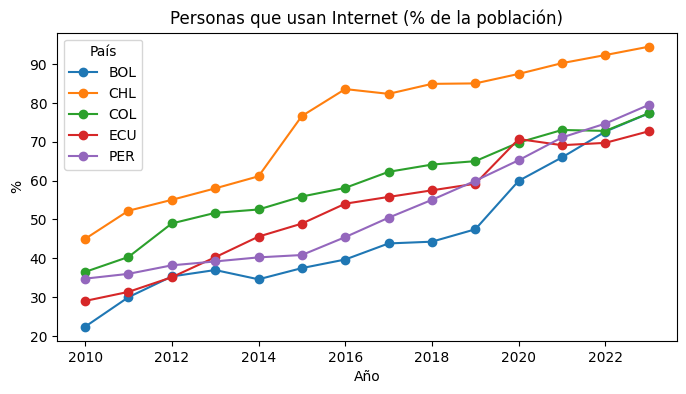

In [13]:
tabla.plot(marker="o", figsize=(8, 4), title="Personas que usan Internet (% de la población)")
plt.xlabel("Año")
plt.ylabel("%")
plt.legend(title="País")
plt.show()

In [14]:
print("Valores faltantes por país:")
print(tabla.isna().sum())

Valores faltantes por país:
iso3
BOL    0
CHL    0
COL    0
ECU    0
PER    0
dtype: int64


Los últimos años pueden no tener dato todavía: los indicadores se publican con retraso. Esto se tratará en la unidad de preparación de datos; por ahora, es suficiente con **identificarlo**.

---
# PARTE 2 · API con API key: ipgeolocation.io
## 2.1 ¿Para qué sirve en redes?
La *IP Geolocation API* recibe una dirección IP y devuelve su ubicación aproximada (país, ciudad, coordenadas), el **sistema autónomo (ASN)** y la organización que administra esa red, la moneda y la zona horaria. En redes y ciberseguridad se usa, por ejemplo, para:
- enriquecer registros (*logs*) de un firewall con el país de origen de las conexiones;
- identificar qué proveedor u organización está detrás de una IP;
- detectar accesos desde ubicaciones inusuales.

**Documentación:** https://ipgeolocation.io/documentation/ip-location-api.html

| Elemento | Valor en esta API |
|---|---|
| Endpoint | `https://api.ipgeolocation.io/v3/ipgeo` |
| Método | `GET` |
| Parámetros | `apiKey` (obligatorio), `ip` (si se omite, consulta la IP de quien hace la solicitud), `fields`, `excludes` |
| Autenticación | **API key** enviada como parámetro |
| Límite del plan gratuito | 1000 créditos por día (1 consulta = 1 crédito) |
| Formato de respuesta | JSON anidado |

## 2.2 Obtener su API key
1. Ingrese a https://ipgeolocation.io y elija el plan gratuito (*Free*).
2. Regístrese con su cuenta de **Google (Gmail)** o **GitHub**.
3. En el panel (*Dashboard*), https://app.ipgeolocation.io/dashboard, copie su **API key**.

## 2.3 Guardar la clave de forma segura
Una API key es una **credencial personal**: identifica a quien hace las consultas y consume su cuota. Por eso:
- **No la escriba directamente en el código** ni la comparta en notebooks, foros o repositorios.
- En **Google Colab**, use **Secretos**: ícono de llave 🔑 del panel izquierdo → *Agregar nuevo secreto* → nombre `IPGEO_API_KEY`, valor = su clave → active el acceso del notebook.
- En Jupyter local, use una variable de entorno o escríbala cuando la celda la solicite (no queda guardada en el archivo).

In [32]:
from getpass import getpass

try:
    from google.colab import userdata                 # solo existe en Google Colab
    API_KEY = userdata.get("IPGEO_API_KEY")           # lee el secreto configurado en el panel 🔑
except Exception:
    # Fuera de Colab: variable de entorno o ingreso oculto por teclado
    API_KEY = os.environ.get("IPGEO_API_KEY") or getpass("Escriba su API key de ipgeolocation.io: ")

print("API key cargada:", "sí" if API_KEY else "no", "| longitud:", len(API_KEY or ""))   # nunca imprima la clave

Escriba su API key de ipgeolocation.io:  ········


API key cargada: sí | longitud: 32


> ⚠️ **Ponga atención:** si su clave queda expuesta (por ejemplo, la compartió por error), **regenérela** desde el panel del proveedor. La clave expuesta debe considerarse comprometida.

## 2.4 Primera consulta
Consultaremos `8.8.8.8`, uno de los servidores DNS públicos de Google.

In [16]:
URL_IPGEO = "https://api.ipgeolocation.io/v3/ipgeo"

r = requests.get(URL_IPGEO, params={"apiKey": API_KEY, "ip": "8.8.8.8"}, timeout=30)

print("Código estado:   ", r.status_code)
print("Content-Type:    ", r.headers.get("Content-Type"))
print("Créditos usados: ", r.headers.get("X-Credits-Charged"))   # encabezado propio del proveedor

geo = r.json()
print("Claves de primer nivel:", list(geo.keys()))

Código estado:    200
Content-Type:     application/json
Créditos usados:  1
Claves de primer nivel: ['ip', 'location', 'country_metadata', 'currency', 'asn', 'time_zone']


In [17]:
# El cuerpo completo: observe los diccionarios anidados
print(json.dumps(geo, indent=2, ensure_ascii=False)[:1500])

{
  "ip": "8.8.8.8",
  "location": {
    "continent_code": "NA",
    "continent_name": "North America",
    "country_code2": "US",
    "country_code3": "USA",
    "country_name": "United States",
    "country_name_official": "United States of America",
    "country_capital": "Washington, D.C.",
    "state_prov": "California",
    "state_code": "US-CA",
    "district": "Santa Clara",
    "city": "Mountain View",
    "zipcode": "94043-1351",
    "latitude": "37.42240",
    "longitude": "-122.08421",
    "is_eu": false,
    "country_flag": "https://ipgeolocation.io/static/flags/us_64.png",
    "geoname_id": "6301403",
    "country_emoji": "🇺🇸"
  },
  "country_metadata": {
    "calling_code": "+1",
    "tld": ".us",
    "languages": [
      "en-US",
      "es-US",
      "haw",
      "fr"
    ]
  },
  "currency": {
    "code": "USD",
    "name": "US Dollar",
    "symbol": "$"
  },
  "asn": {
    "as_number": "AS15169",
    "organization": "Google LLC",
    "country": "US"
  },
  "time_zone"

## 2.5 Navegar el JSON anidado

In [18]:
print("IP:          ", geo["ip"])
print("País:        ", geo["location"]["country_name"])
print("Ciudad:      ", geo["location"]["city"])
print("Coordenadas: ", geo["location"]["latitude"], geo["location"]["longitude"])
print("ASN:         ", geo["asn"]["as_number"], "-", geo["asn"]["organization"])
print("Zona horaria:", geo["time_zone"]["name"])

IP:           8.8.8.8
País:         United States
Ciudad:       Mountain View
Coordenadas:  37.42240 -122.08421
ASN:          AS15169 - Google LLC
Zona horaria: America/Los_Angeles


In [19]:
# .get() evita un KeyError si una clave no viene en la respuesta (p. ej., campos que dependen del plan)
print("ISP:", geo.get("isp", "no incluido en esta respuesta"))

ISP: no incluido en esta respuesta


> ⚠️ **Ponga atención:** la estructura de la respuesta puede variar según el plan o la versión de la API. Use `.get()` para claves opcionales y revise la documentación si una clave no aparece.

## 2.6 Códigos de estado y errores
Provocamos errores a propósito para aprender a reconocerlos:

| Código | Significado general | Ejemplo en esta API |
|---|---|---|
| 200 | Solicitud exitosa | IP pública válida con API key válida |
| 400 | Solicitud incorrecta | IP mal escrita |
| 401 | No autorizado | API key ausente o inválida |
| 423 | Recurso bloqueado | IP privada o reservada (p. ej., `192.168.1.1`), que no tiene ubicación pública |
| 429 | Demasiadas solicitudes | Se agotó la cuota diaria |

In [20]:
pruebas = {
    "sin API key":     {"ip": "8.8.8.8"},
    "IP mal escrita":  {"apiKey": API_KEY, "ip": "8.8.8"},
    "IP privada":      {"apiKey": API_KEY, "ip": "192.168.1.1"},
}

for caso, parametros in pruebas.items():
    r = requests.get(URL_IPGEO, params=parametros, timeout=30)
    try:
        mensaje = r.json().get("message", "")         # la API explica el error en 'message'
    except ValueError:                                # el cuerpo no es JSON
        mensaje = r.text
    print(f"{caso:16} -> {r.status_code}: {mensaje[:90]}")
    time.sleep(1)

sin API key      -> 401: Please provide an API key (as 'apiKey=YOUR_API_KEY' URL parameter) to use IPGeolocation AP
IP mal escrita   -> 401: IP to geolocation lookup for domain or service name is not supported on your current subsc
IP privada       -> 423: '192.168.1.1' is a bogon IP address.


> ⚠️ **Ponga atención:** la IP `192.168.1.1` que usa en su casa o laboratorio es **privada**: solo tiene sentido dentro de su red local, por eso no se puede geolocalizar. Solo las IP **públicas** tienen información en estas bases de datos.

## 2.7 Consultar varias IP y construir un DataFrame
Encapsulamos la consulta en una función que valida la respuesta y extrae solo los campos de interés.

In [21]:
def consultar_ip(ip, api_key=API_KEY, crudas=None):
    """Consulta ipgeolocation.io y devuelve un diccionario plano con los campos de interés, o None si falla.
    Si se entrega la lista 'crudas', agrega en ella la respuesta completa (para guardarla después)."""
    try:
        r = requests.get(URL_IPGEO, params={"apiKey": api_key, "ip": ip}, timeout=30)
    except requests.exceptions.RequestException as e:
        print(f"{ip}: error de conexión ({e})")
        return None

    if r.status_code != 200:
        try:
            mensaje = r.json().get("message", "")
        except ValueError:                # algunos errores llegan como texto o HTML, no como JSON
            mensaje = r.text
        print(f"{ip}: código {r.status_code} - {mensaje[:80]}")
        return None

    d = r.json()
    if crudas is not None:
        crudas.append(d)                  # conservamos la respuesta original
    loc, asn = d.get("location", {}), d.get("asn", {})
    return {
        "ip": d.get("ip"),
        "pais": loc.get("country_name"),
        "codigo_pais": loc.get("country_code2"),
        "ciudad": loc.get("city"),
        "latitud": float(loc.get("latitude", "nan")),
        "longitud": float(loc.get("longitude", "nan")),
        "asn": asn.get("as_number"),
        "organizacion": asn.get("organization"),
        "zona_horaria": d.get("time_zone", {}).get("name"),
    }


# Servidores DNS públicos conocidos (y una IP privada para ver cómo se maneja el error)
ips = ["8.8.8.8", "1.1.1.1", "9.9.9.9", "208.67.222.222", "192.168.1.1"]

resultados, respuestas_crudas = [], []
for ip in ips:
    fila = consultar_ip(ip, crudas=respuestas_crudas)
    if fila:                              # solo se agregan las consultas exitosas
        resultados.append(fila)
    time.sleep(1)                         # 1 consulta por segundo: uso responsable

df_ips = pd.DataFrame(resultados)
df_ips

192.168.1.1: código 423 - '192.168.1.1' is a bogon IP address.


,ip,pais,codigo_pais,ciudad,latitud,longitud,asn,organizacion,zona_horaria
0,8.8.8.8,United States,US,Mountain View,37.42240,-122.08421,AS15169,Google LLC,America/Los_Angeles
1,1.1.1.1,Australia,AU,South Brisbane,-27.47301,153.01425,AS13335,"Cloudflare, Inc.",Australia/Brisbane
2,9.9.9.9,United States,US,Ninnescah,37.75140,-97.82311,AS19281,Quad9,America/Chicago
3,208.67.222.222,United States,US,San Jose,37.40914,-121.95273,AS36692,"Cisco OpenDNS, LLC",America/Los_Angeles


> ⚠️ **Ponga atención**
> - Cada consulta exitosa consume **1 crédito** de su cuota diaria. Evite ejecutar los ciclos muchas veces y no consulte miles de IP en el plan gratuito.
> - La geolocalización por IP es **aproximada**: para servicios distribuidos (como los DNS públicos, que usan *anycast*) la ubicación corresponde al registro de la organización, no necesariamente al servidor que le responde.

### Alternativa: `json_normalize` sobre las respuestas completas
Si prefiere conservar todos los campos, aplane las respuestas completas que se guardaron en `respuestas_crudas`.

In [22]:
# respuestas_crudas se llenó en la celda anterior: no se gastan créditos adicionales
plano = pd.json_normalize(respuestas_crudas)
print(plano.shape)
print(plano.columns.tolist()[:15], "...")

(4, 54)
['ip', 'location.continent_code', 'location.continent_name', 'location.country_code2', 'location.country_code3', 'location.country_name', 'location.country_name_official', 'location.country_capital', 'location.state_prov', 'location.state_code', 'location.district', 'location.city', 'location.zipcode', 'location.latitude', 'location.longitude'] ...


---
# PARTE 3 · Escritura persistente (apartado 2.3)
Consultar una API cuesta tiempo y cuota. Por eso, después de extraer y organizar los datos, conviene **guardarlos**: así se pueden reutilizar, compartir y comparar con capturas futuras sin volver a consultar la fuente.

Guardaremos tres cosas:
1. la **respuesta cruda** (tal como llegó), para trazabilidad;
2. los **datos procesados** (DataFrame), en formatos de uso habitual;
3. los **metadatos**: de dónde, cuándo y cómo se obtuvieron los datos.

## 3.1 Guardar la respuesta cruda (JSON)

In [23]:
with open("datos/bm_internet_crudo.json", "w", encoding="utf-8") as f:
    json.dump(crudos_internet, f, ensure_ascii=False, indent=1)

with open("datos/ipgeo_crudo.json", "w", encoding="utf-8") as f:
    json.dump(respuestas_crudas, f, ensure_ascii=False, indent=1)

print(os.listdir("datos"))

['ipgeo_crudo.json', 'bm_internet_crudo.json']


## 3.2 Guardar los datos procesados

In [24]:
# CSV: tabular, fácil de abrir en Excel u otros programas
df_internet.to_csv("datos/bm_internet.csv", index=False)
df_ips.to_csv("datos/ipgeo_dns.csv", index=False)

# JSON por registros: útil para intercambiar con aplicaciones y APIs
df_ips.to_json("datos/ipgeo_dns.json", orient="records", indent=1, force_ascii=False)

# Parquet: columnar y comprimido; conserva los tipos (requiere pyarrow, ya incluido en Colab)
try:
    df_internet.to_parquet("datos/bm_internet.parquet", index=False)
except ImportError:
    print("pyarrow no está instalado: se omite Parquet")

for archivo in sorted(os.listdir("datos")):
    print(f"{archivo:28} {os.path.getsize('datos/' + archivo):>8,} bytes")

bm_internet.csv                 3,076 bytes
bm_internet.parquet             4,375 bytes
bm_internet_crudo.json         20,611 bytes
ipgeo_crudo.json                7,227 bytes
ipgeo_dns.csv                     466 bytes
ipgeo_dns.json                    950 bytes


## 3.3 Guardar los metadatos
Un dataset sin contexto pierde valor: más adelante no sabremos si sigue vigente ni cómo se obtuvo. Registramos la fuente, la licencia, el responsable, la fecha de extracción y los parámetros de la consulta.

In [25]:
fecha_extraccion = datetime.now(timezone.utc).isoformat(timespec="seconds")

metadatos = [
    {
        "archivo": "bm_internet.csv",
        "fuente": "Banco Mundial - Indicators API",
        "endpoint": URL_BASE_BM + f"country/{PAISES}/indicator/{INDICADOR}",
        "parametros": {"format": "json", "date": "2010:2023"},
        "descripcion": "Personas que usan Internet (% de la población)",
        "licencia": "CC BY 4.0",
        "fecha_extraccion_utc": fecha_extraccion,
        "registros": len(df_internet),
        "responsable": "Escriba aquí su nombre",
    },
    {
        "archivo": "ipgeo_dns.csv",
        "fuente": "ipgeolocation.io - IP Geolocation API v3",
        "endpoint": URL_IPGEO,
        "parametros": {"ip": ips},                 # ¡nunca guarde la API key en los metadatos!
        "descripcion": "Geolocalización y ASN de servidores DNS públicos",
        "licencia": "Sujeta a los términos de uso de ipgeolocation.io",
        "fecha_extraccion_utc": fecha_extraccion,
        "registros": len(df_ips),
        "responsable": "Escriba aquí su nombre",
    },
]

with open("datos/metadatos.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)

print(json.dumps(metadatos[0], ensure_ascii=False, indent=2))

{
  "archivo": "bm_internet.csv",
  "fuente": "Banco Mundial - Indicators API",
  "endpoint": "https://api.worldbank.org/v2/country/ECU;PER;COL;BOL;CHL/indicator/IT.NET.USER.ZS",
  "parametros": {
    "format": "json",
    "date": "2010:2023"
  },
  "descripcion": "Personas que usan Internet (% de la población)",
  "licencia": "CC BY 4.0",
  "fecha_extraccion_utc": "2026-10-29T22:18:03+00:00",
  "registros": 70,
  "responsable": "Escriba aquí su nombre"
}


> ⚠️ **Ponga atención:** **nunca** guarde la API key en archivos de datos, metadatos ni en el notebook. Revise lo que guarda antes de compartirlo.

## 3.4 Verificar que los datos se recuperan correctamente

In [26]:
recuperado = pd.read_csv("datos/bm_internet.csv")
print("CSV recuperado:", recuperado.shape, "| igual al original:", recuperado.equals(df_internet))

recuperado_json = pd.read_json("datos/ipgeo_dns.json")
print("JSON recuperado:", recuperado_json.shape)

with open("datos/metadatos.json", encoding="utf-8") as f:
    print("Metadatos de:", [m["archivo"] for m in json.load(f)])

CSV recuperado: (70, 5) | igual al original: True
JSON recuperado: (4, 9)
Metadatos de: ['bm_internet.csv', 'ipgeo_dns.csv']


## 3.5 ¿Qué formato elegir?

| Formato | Conviene cuando… | Limitación |
|---|---|---|
| CSV | Datos tabulares simples que se compartirán o abrirán en Excel | No conserva tipos; no admite estructuras anidadas |
| JSON | Datos semiestructurados o anidados, como respuestas de APIs | Ocupa más espacio; menos cómodo para análisis tabular |
| Parquet | Volúmenes grandes y análisis repetidos en Python | No se abre con un editor de texto |
| Base de datos (SQL / NoSQL) | Datos que se actualizan con frecuencia o se consultan de forma concurrente | Requiere instalar y administrar un motor |

> 💡 En Colab, la carpeta `datos/` se borra al cerrar la sesión. Descargue los archivos (panel 📁 → clic derecho → *Descargar*) o guárdelos en Google Drive.

---
# PARTE 4 · Ejercicios
Resuelva cada ejercicio en la celda indicada y **comente su código**.

### Ejercicio 1 · Banco Mundial: nuevo indicador
Use `obtener_indicador()` para descargar las **suscripciones a telefonía celular móvil** (`IT.CEL.SETS.P2`) de Ecuador, Perú, Colombia, Argentina y Uruguay entre 2015 y 2023.
a) ¿Cuántos registros obtuvo? ¿Cuántas páginas tuvo que recorrer la función?
b) ¿Qué país tuvo el valor más alto en 2022?
c) ¿Por qué un país puede tener más de 100 suscripciones por cada 100 personas?

In [27]:
# Ejercicio 1

### Ejercicio 2 · Banco Mundial: dos indicadores en una tabla
Descargue `IT.NET.USER.ZS` e `IT.NET.BBND.P2` para Ecuador (2010–2023) y combínelos en un solo DataFrame con las columnas `anio`, `internet_pct` y `banda_ancha_100`. *Pista:* `pd.merge(df1, df2, on="anio")`. Construya un gráfico de líneas con ambos indicadores.

In [28]:
# Ejercicio 2

### Ejercicio 3 · ipgeolocation: sus propias IP
a) Use `consultar_ip()` con estas IP públicas: `8.8.4.4`, `1.0.0.1`, `149.112.112.112`, `208.67.220.220`. Construya un DataFrame.
b) Agrupe por `organizacion` y cuente cuántas IP tiene cada una.
c) Consulte la API **sin** el parámetro `ip`: ¿qué IP se geolocalizó? ¿Por qué? (Si trabaja en Colab, piense dónde se ejecuta realmente el código).

In [29]:
# Ejercicio 3

### Ejercicio 4 · Manejo de errores
Escriba una función `validar_respuesta(r)` que reciba un objeto `Response` y devuelva un mensaje en español según el código de estado (200, 400, 401, 404, 423, 429 u otro). Pruébela con al menos tres solicitudes que produzcan códigos distintos.

In [30]:
# Ejercicio 4

### Ejercicio 5 · Escritura persistente con metadatos
Guarde los resultados de los ejercicios 1 y 3 en CSV y en JSON (`orient="records"`) dentro de la carpeta `datos/`. Agregue sus entradas a `metadatos.json` (fuente, endpoint, parámetros, licencia, fecha de extracción, número de registros y responsable). Verifique que todos los archivos se puedan volver a leer.

In [31]:
# Ejercicio 5

### Reflexión
Responda brevemente:
1. ¿Qué tan fácil o difícil fue interpretar la documentación de cada API?
2. ¿Qué estructura tenían los datos obtenidos y cómo los transformó en una tabla?
3. ¿Qué ventajas ofrece pandas para organizarlos?
4. ¿Qué formato de guardado eligió y por qué?
5. ¿Qué riesgos implica compartir una API key y cómo los evitó?

*Sus respuestas:*

## Resumen
- Antes de programar, revise la documentación: **endpoint, parámetros, autenticación, límites y formato** de respuesta.
- `requests.get(url, params=..., timeout=...)` envía la solicitud; valide `status_code` **y** el contenido.
- `respuesta.json()` convierte el cuerpo en listas y diccionarios; `pd.json_normalize()` aplana el JSON anidado en un DataFrame.
- Recorra todas las páginas cuando la API pagina los resultados.
- Proteja su API key: use secretos o variables de entorno, nunca la escriba en el código.
- Guarde la respuesta cruda, los datos procesados y sus **metadatos** para asegurar la trazabilidad.

**Fuentes:** Banco Mundial, *Indicators API* (CC BY 4.0); ipgeolocation.io, *IP Geolocation API*.